# Workshop 5 - Training Pipeline (Fashion-MNIST, Team 3)

Documentation notebook for the training stage of Workshop 5. It covers the complete adversarial pipeline end to end - data preparation in `[-1, 1]`, Generator/Discriminator/Critic definitions, the Vanilla GAN and WGAN-GP objectives, sample generation, quality evaluation and the downstream augmentation experiment - and doubles as a runnable reference: every cell calls the same code as the CLI (`src.data`, `src.gan`, `src.train_gan`, `src.generate_samples`, `src.evaluate_gan`, `src.augment_and_retrain`), so the flow shown here is the flow behind the reported results.

**How this notebook is meant to be used**

- `DEMO = True` runs a short 2-epoch demonstration with a limited number of batches (about 1-2 minutes on Apple MPS). Demo artifacts are isolated in `runs/notebook_demo/` and `checkpoints/notebook_demo/`, so the real checkpoints and logs are never overwritten.
- The full experiments are launched from the command line (Section 11): Vanilla GAN, 100 epochs; WGAN-GP, 100 epochs with `n_critic = 5` and `lambda_gp = 10`.
- Requirement mapping: architectures and parameter counts (Section 3), training strategy (Section 4), Vanilla GAN training (Section 5), WGAN-GP training (Section 6), sample generation (Section 7), quality metrics (Section 8), augmentation experiment (Section 9), checkpoint verification (Section 10).

## 0. Configuration

Centralized run parameters, so a change here is enough to reproduce a different configuration:

| Parameter | Demo value | Full runs |
|---|---|---|
| `DEMO` | `True` | `False` |
| `DEMO_EPOCHS` | 2 | 100 (both models) |
| `DEMO_BATCHES` | 20 | `None` (all 95 batches of 512) |
| `BATCH_SIZE` | 128 (CPU/MPS friendly) | 512 |
| `Z_DIM` | 100 | 100 |
| `LR` | 2e-4 | 2e-4 |
| `LABEL_SMOOTHING` | 0.9 | 0.9 |
| `N_CRITIC` | 2 (demo) | 5 |
| `LAMBDA_GP` | 10.0 | 10.0 |
| `SEED` | 42 | 42 |

`NUM_WORKERS = 0` keeps the DataLoader single-process, the reliable option for notebooks on Windows. The demo uses fewer batches only to keep the notebook interactive; the optimization code is identical.

In [1]:
DEMO = False

DEMO_EPOCHS = 2 if DEMO else 100
DEMO_BATCHES = 20 if DEMO else None
BATCH_SIZE = 128 if DEMO else 512
Z_DIM = 100
LR = 2e-4
LABEL_SMOOTHING = 0.9
N_CRITIC = 2 if DEMO else 5
LAMBDA_GP = 10.0
SEED = 42
NUM_WORKERS = 0
EVAL_SAMPLES = 1000 if DEMO else 5000

## 1. Environment

The notebook runs on the project virtual environment (`Workshop_5/.venv`, installed with `pip install -e .`). The cell below reports the Python/torch versions and selects the accelerator through `src.gan.pick_device`, which prefers CUDA, then Apple MPS, then the DirectML GPU when available, and otherwise falls back to CPU.

Reproducibility starts here: `set_seed` fixes the Python, NumPy and torch RNGs (seed 42) and the data split is cached in `Workshop_2/data/splits.json` and reloaded instead of recomputed.

In [2]:
import json
import os
import sys
import time
from pathlib import Path

if Path.cwd().name == "notebooks":       # allow running from notebooks/ or Workshop_5/
    os.chdir("..")
BASE = Path.cwd()
if str(BASE) not in sys.path:
    sys.path.insert(0, str(BASE))

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Image, display

from src.augment_and_retrain import build_synthetic_labeled_set
from src.data import CLASS_NAMES, get_full_dataset, get_splits
from src.evaluate_gan import (
    compute_diversity_and_coverage,
    compute_frechet_distance,
    compute_inception_score,
    extract_features_and_probs,
    load_w2_evaluator,
)
from src.gan import (
    Critic,
    Discriminator,
    Generator,
    compute_gradient_penalty,
    count_parameters,
    load_generator_checkpoint,
    pick_device,
    set_seed,
)
from src.generate_samples import plot_side_by_side_grid, sample_from_generator
from src.train_gan import plot_gan_training_curves, train_vanilla_gan, train_wgan_gp

%matplotlib inline

set_seed(SEED)
device = pick_device("auto")
print(f"python {sys.version.split()[0]} | torch {torch.__version__} | device: {device}")

python 3.12.14 | torch 2.14.0 | device: mps


## 2. Data - the shared Fashion-MNIST protocol

The dataset is Fashion-MNIST (70,000 grayscale 28x28 images, 10 balanced classes). Workshop 5 reuses the exact Workshop 2 stratified **70 / 15 / 15** split (49,000 / 10,500 / 10,500, seed 42), but changes the scaling because the Generator ends in `Tanh`:

| Item | Value |
|---|---|
| Split | stratified 70/15/15 - 49,000 / 10,500 / 10,500 (seed 42) |
| GAN scaling | pixels mapped from `[0, 255]` to `[-1, 1]` with `x / 127.5 - 1` |
| W2 classifier scaling | pixels in `[0, 1]`, then z-score with mean 0.2860 / std 0.3530 |
| Train augmentation (W2 retraining only) | horizontal flip p=0.5 + translation +/-2 px |

Keeping the identical split means the downstream classifier comparison is paired: every condition sees the same validation and test images.

[data] reusing cached split from /Users/jhojan/Documents/Universidad/Semestre10/MachineLearning/Workshops/MachineLearning/Workshop_2/data/splits.json
train=49,000  val=10,500  test=10,500 samples
GAN tensor: (49000, 1, 28, 28) | range [-1.00, 1.00]
class counts (train): [4900, 4900, 4900, 4900, 4900, 4900, 4900, 4900, 4900, 4900]


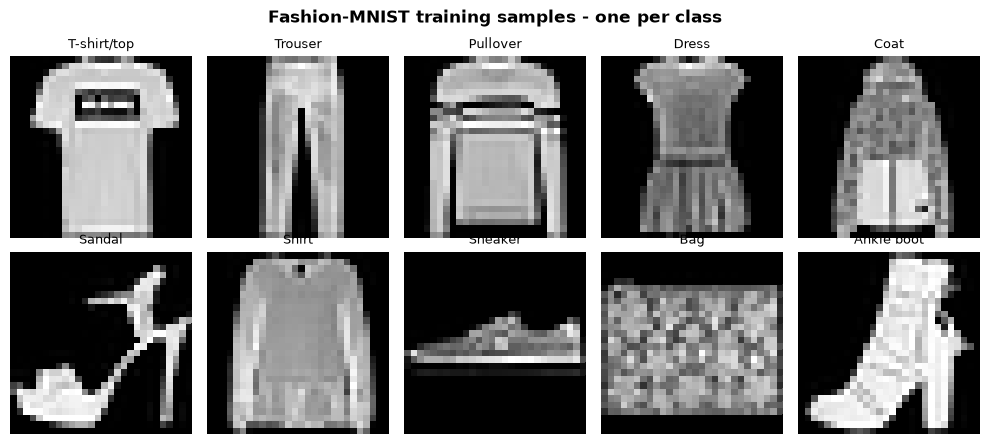

In [3]:
images, labels = get_full_dataset()
splits = get_splits(labels, seed=SEED)

train_idx = np.asarray(splits["train"], dtype=np.int64)
val_idx = np.asarray(splits["val"], dtype=np.int64)
test_idx = np.asarray(splits["test"], dtype=np.int64)

x_train = torch.from_numpy(images[train_idx]).unsqueeze(1).float().div_(127.5).sub_(1.0).contiguous()
y_train = torch.from_numpy(labels[train_idx]).long().contiguous()
real_test = images[test_idx].astype(np.float32) / 255.0

print(f"train={len(train_idx):,}  val={len(val_idx):,}  test={len(test_idx):,} samples")
print(f"GAN tensor: {tuple(x_train.shape)} | range [{x_train.min():.2f}, {x_train.max():.2f}]")
print("class counts (train):", np.bincount(labels[train_idx], minlength=10).tolist())

fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for ax, class_id in zip(axes.ravel(), range(10)):
    first = int(np.where(labels[train_idx] == class_id)[0][0])
    ax.imshow(images[train_idx[first]], cmap="gray")
    ax.set_title(CLASS_NAMES[class_id], fontsize=9)
    ax.axis("off")
fig.suptitle("Fashion-MNIST training samples - one per class", fontweight="bold")
fig.tight_layout()
plt.show()

## 3. Architectures - Generator, Discriminator and Critic

All three networks follow the DCGAN design rules: the generator projects the noise vector to a `128 x 7 x 7` map, upsamples with two strided transpose convolutions (`7 -> 14 -> 28`), uses BatchNorm + ReLU, and ends with a `3 x 3` convolution + `Tanh` so the output lives in `[-1, 1]`.

The Discriminator and the WGAN-GP Critic share the same convolutional trunk (three strided convolutions down to `128 x 4 x 4`, LeakyReLU 0.2) and differ exactly where the theory requires:

| Component | Vanilla Discriminator | WGAN-GP Critic |
|---|---|---|
| Normalization | BatchNorm2d | InstanceNorm2d (affine) |
| Regularization | Dropout(0.3) before the head | none |
| Output | Linear -> Sigmoid (probability) | Linear (unconstrained score) |
| Loss | BCE + one-sided label smoothing 0.9 | Wasserstein + gradient penalty (lambda=10) |
| Optimizer | Adam 2e-4, beta1=0.5 | Adam 2e-4, beta1=0.0 |
| Ratio | 1 D step per G step | `n_critic = 5` C steps per G step |

In [4]:
G = Generator(z_dim=Z_DIM)
D = Discriminator()
C = Critic()

z = torch.randn(8, Z_DIM)
fake = G(z)
gp = compute_gradient_penalty(C, torch.randn_like(fake), fake)

print(f"Generator      : params={count_parameters(G)[0]:,} | output={tuple(fake.shape)} | range=[{fake.min():.2f}, {fake.max():.2f}]")
print(f"Discriminator  : params={count_parameters(D)[0]:,} | output={tuple(D(fake).shape)} (probabilities)")
print(f"Critic         : params={count_parameters(C)[0]:,} | output={tuple(C(fake).shape)} (unconstrained scores)")
print(f"Gradient penalty on random pairs: {gp.item():.3f} (lambda=10)")

Generator      : params=804,065 | output=(8, 1, 28, 28) | range=[-0.77, 0.48]
Discriminator  : params=109,473 | output=(8,) (probabilities)
Critic         : params=109,473 | output=(8,) (unconstrained scores)
Gradient penalty on random pairs: 16.890 (lambda=10)


## 4. Training strategy

| Component | Vanilla GAN | WGAN-GP |
|---|---|---|
| Objective | `min_G max_D E[log D(x)] + E[log(1 - D(G(z)))]` | `max_C E[C(x)] - E[C(G(z))] - lambda * GP` |
| Loss | BCE with one-sided label smoothing (real target 0.9) | Wasserstein estimate + gradient penalty |
| Generator optimizer | Adam, lr 2e-4, beta=(0.5, 0.999) | Adam, lr 2e-4, beta=(0.0, 0.9) |
| Critic/Discriminator optimizer | Adam, lr 2e-4, beta=(0.5, 0.999) | Adam, lr 2e-4, beta=(0.0, 0.9) |
| Epochs (full runs) | 100 | 100 |
| Batch size (full runs) | 512 | 512 |
| Monitoring | BCE losses + D accuracy on real/fake | Wasserstein distance + gradient penalty + G loss |
| Samples | fixed 64-noise grid every 10 epochs | fixed 64-noise grid every 10 epochs |

The full runs use the same data order, seed and architecture for both models, so the comparison isolates the objective. The notebook demo keeps the same code path but limits the number of batches.

In [5]:
run_root = BASE / "runs" / "notebook_demo"
ckpt_root = BASE / "checkpoints" / "notebook_demo"
run_root.mkdir(parents=True, exist_ok=True)
ckpt_root.mkdir(parents=True, exist_ok=True)

config = dict(
    demo=DEMO,
    epochs=DEMO_EPOCHS,
    max_batches_per_epoch=DEMO_BATCHES,
    batch_size=BATCH_SIZE,
    z_dim=Z_DIM,
    lr=LR,
    label_smoothing=LABEL_SMOOTHING,
    n_critic=N_CRITIC,
    lambda_gp=LAMBDA_GP,
    seed=SEED,
    device=str(device),
)
print(json.dumps(config, indent=2))

{
  "demo": false,
  "epochs": 100,
  "max_batches_per_epoch": null,
  "batch_size": 512,
  "z_dim": 100,
  "lr": 0.0002,
  "label_smoothing": 0.9,
  "n_critic": 5,
  "lambda_gp": 10.0,
  "seed": 42,
  "device": "mps"
}


## 5. Vanilla GAN - demo training

The Vanilla GAN trains the Discriminator with BCE and one-sided label smoothing: real images are labelled `0.9` instead of `1.0`, so the discriminator never becomes overconfident and the generator keeps receiving informative gradients. The cell below logs the discriminator/generator losses and the discriminator accuracy on real and fake batches, exactly like `src/train_gan.py`.

The demo writes only to `checkpoints/notebook_demo/` and `runs/notebook_demo/vanilla_gan/`.

In [6]:
t0 = time.time()
vanilla_demo = train_vanilla_gan(
    epochs=DEMO_EPOCHS,
    batch_size=BATCH_SIZE,
    z_dim=Z_DIM,
    lr=LR,
    label_smoothing=LABEL_SMOOTHING,
    sample_interval=1 if DEMO else 10,
    max_batches_per_epoch=DEMO_BATCHES,
    seed=SEED,
    device_name="auto",
    checkpoint_dir=ckpt_root,
    runs_dir=run_root,
    cached_data=(x_train, y_train),
)
print(f"demo finished in {time.time() - t0:.1f}s")

[train_gan] model=vanilla_gan | epochs=100 batch=512 lr=0.0002 smooth=0.9 | G_params=804,065 D_params=109,473 | device=mps
  ep 001/100 | d_loss=0.4283 g_loss=1.9318 | d_acc_real=80.1% d_acc_fake=92.0% (11.9s)
  ep 010/100 | d_loss=0.5836 g_loss=1.2100 | d_acc_real=60.5% d_acc_fake=80.6% (10.3s)
  ep 020/100 | d_loss=0.5930 g_loss=1.1904 | d_acc_real=58.7% d_acc_fake=80.3% (11.0s)
  ep 030/100 | d_loss=0.5984 g_loss=1.1874 | d_acc_real=58.4% d_acc_fake=79.4% (11.9s)
  ep 040/100 | d_loss=0.5953 g_loss=1.2019 | d_acc_real=58.4% d_acc_fake=79.2% (12.1s)
  ep 050/100 | d_loss=0.5910 g_loss=1.2135 | d_acc_real=59.1% d_acc_fake=79.8% (12.5s)
  ep 060/100 | d_loss=0.5919 g_loss=1.2258 | d_acc_real=59.3% d_acc_fake=79.4% (12.4s)
  ep 070/100 | d_loss=0.6047 g_loss=1.2148 | d_acc_real=58.5% d_acc_fake=78.8% (12.8s)
  ep 080/100 | d_loss=0.5905 g_loss=1.2553 | d_acc_real=59.9% d_acc_fake=79.0% (13.8s)
  ep 090/100 | d_loss=0.5764 g_loss=1.2885 | d_acc_real=61.2% d_acc_fake=80.5% (15.2s)
  ep 10

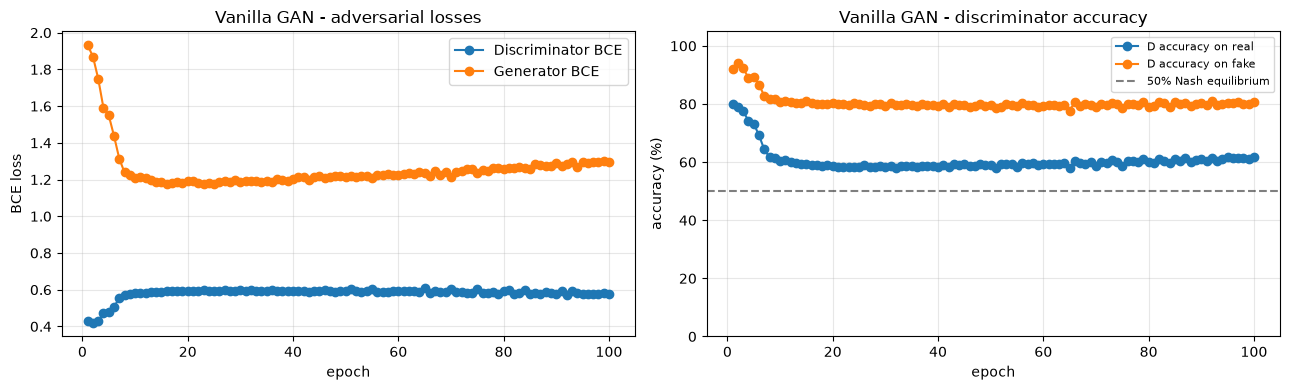

In [7]:
hist = vanilla_demo["history"]
epochs = [r["epoch"] for r in hist]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.0))
axes[0].plot(epochs, [r["d_loss"] for r in hist], marker="o", label="Discriminator BCE")
axes[0].plot(epochs, [r["g_loss"] for r in hist], marker="o", label="Generator BCE")
axes[0].set_title("Vanilla GAN - adversarial losses")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("BCE loss")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(epochs, [r["d_acc_real"] * 100 for r in hist], marker="o", label="D accuracy on real")
axes[1].plot(epochs, [r["d_acc_fake"] * 100 for r in hist], marker="o", label="D accuracy on fake")
axes[1].axhline(50, color="black", linestyle="--", alpha=0.5, label="50% Nash equilibrium")
axes[1].set_title("Vanilla GAN - discriminator accuracy")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("accuracy (%)")
axes[1].set_ylim(0, 105)
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=8)

fig.tight_layout()
plt.show()

## 6. WGAN-GP - demo training

WGAN-GP replaces the BCE game with the Wasserstein objective and enforces the 1-Lipschitz constraint through a gradient penalty. The critic is trained `n_critic` times for every generator step; the penalty interpolates between real and generated samples:

$$\hat{x} = \epsilon x + (1 - \epsilon) G(z), \qquad \epsilon \sim U[0,1], \qquad GP = \lambda \, E[(\|\nabla_{\hat{x}} C(\hat{x})\|_2 - 1)^2]$$

The informative curves are the **Wasserstein distance** (should trend down) and the **gradient penalty** (should shrink); the raw generator loss `-E[C(G(z))]` can grow while samples improve, which is why it must not be read as a quality metric on its own.

In [8]:
t0 = time.time()
wgan_demo = train_wgan_gp(
    epochs=DEMO_EPOCHS,
    batch_size=BATCH_SIZE,
    z_dim=Z_DIM,
    lr=LR,
    n_critic=N_CRITIC,
    lambda_gp=LAMBDA_GP,
    sample_interval=1 if DEMO else 10,
    max_batches_per_epoch=10 if DEMO else None,
    seed=SEED,
    device_name="auto",
    checkpoint_dir=ckpt_root,
    runs_dir=run_root,
    cached_data=(x_train, y_train),
)
print(f"demo finished in {time.time() - t0:.1f}s")

[train_gan] model=wgan_gp | epochs=100 batch=512 lr=0.0002 n_critic=5 lambda_gp=10.0 | G_params=804,065 C_params=109,473 | device=mps
  ep 001/100 | W_dist=4.7504 critic_loss=-1.3523 gp=3.3981 g_loss=3.9644 (39.7s)
  ep 010/100 | W_dist=6.0113 critic_loss=-5.2116 gp=0.7996 g_loss=11.7860 (43.2s)
  ep 020/100 | W_dist=4.1617 critic_loss=-3.6663 gp=0.4953 g_loss=12.0619 (43.6s)
  ep 030/100 | W_dist=3.4447 critic_loss=-3.0391 gp=0.4056 g_loss=12.6561 (48.7s)
  ep 040/100 | W_dist=3.1415 critic_loss=-2.7662 gp=0.3754 g_loss=14.3778 (44.1s)
  ep 050/100 | W_dist=2.8837 critic_loss=-2.5371 gp=0.3466 g_loss=16.0273 (45.1s)
  ep 060/100 | W_dist=2.7011 critic_loss=-2.3790 gp=0.3221 g_loss=16.9653 (45.6s)
  ep 070/100 | W_dist=2.5487 critic_loss=-2.2435 gp=0.3052 g_loss=18.2887 (45.5s)
  ep 080/100 | W_dist=2.3893 critic_loss=-2.1071 gp=0.2822 g_loss=19.3452 (46.5s)
  ep 090/100 | W_dist=2.2854 critic_loss=-2.0135 gp=0.2719 g_loss=20.6692 (47.3s)
  ep 100/100 | W_dist=2.1664 critic_loss=-1.910

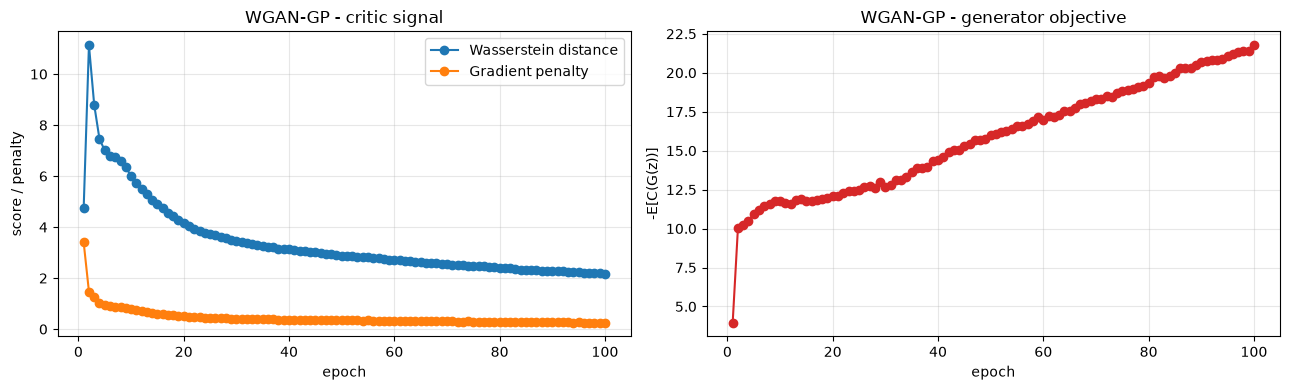

In [9]:
wh = wgan_demo["history"]
wepochs = [r["epoch"] for r in wh]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.0))
axes[0].plot(wepochs, [r["wasserstein_dist"] for r in wh], marker="o", label="Wasserstein distance")
axes[0].plot(wepochs, [r["gp_loss"] for r in wh], marker="o", label="Gradient penalty")
axes[0].set_title("WGAN-GP - critic signal")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("score / penalty")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(wepochs, [r["g_loss"] for r in wh], marker="o", color="#d62728")
axes[1].set_title("WGAN-GP - generator objective")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("-E[C(G(z))]")
axes[1].grid(alpha=0.3)

fig.tight_layout()
plt.show()

## 7. Sample generation from the full checkpoints

The reported runs stored two generators:

- `checkpoints/gan_vanilla_best.pt` - Vanilla DCGAN, 100 epochs.
- `checkpoints/gan_wgan_best.pt` - WGAN-GP, 100 epochs.

The function below loads the generator state and samples from `z ~ N(0, I)`. The side-by-side grid puts real test images next to both models so the qualitative comparison uses the same layout as the report.

[generate_samples] saved 4x4 grid -> /Users/jhojan/Documents/Universidad/Semestre10/MachineLearning/Workshops/MachineLearning/Workshop_5/runs/notebook_demo/sample_grid_4x4.png


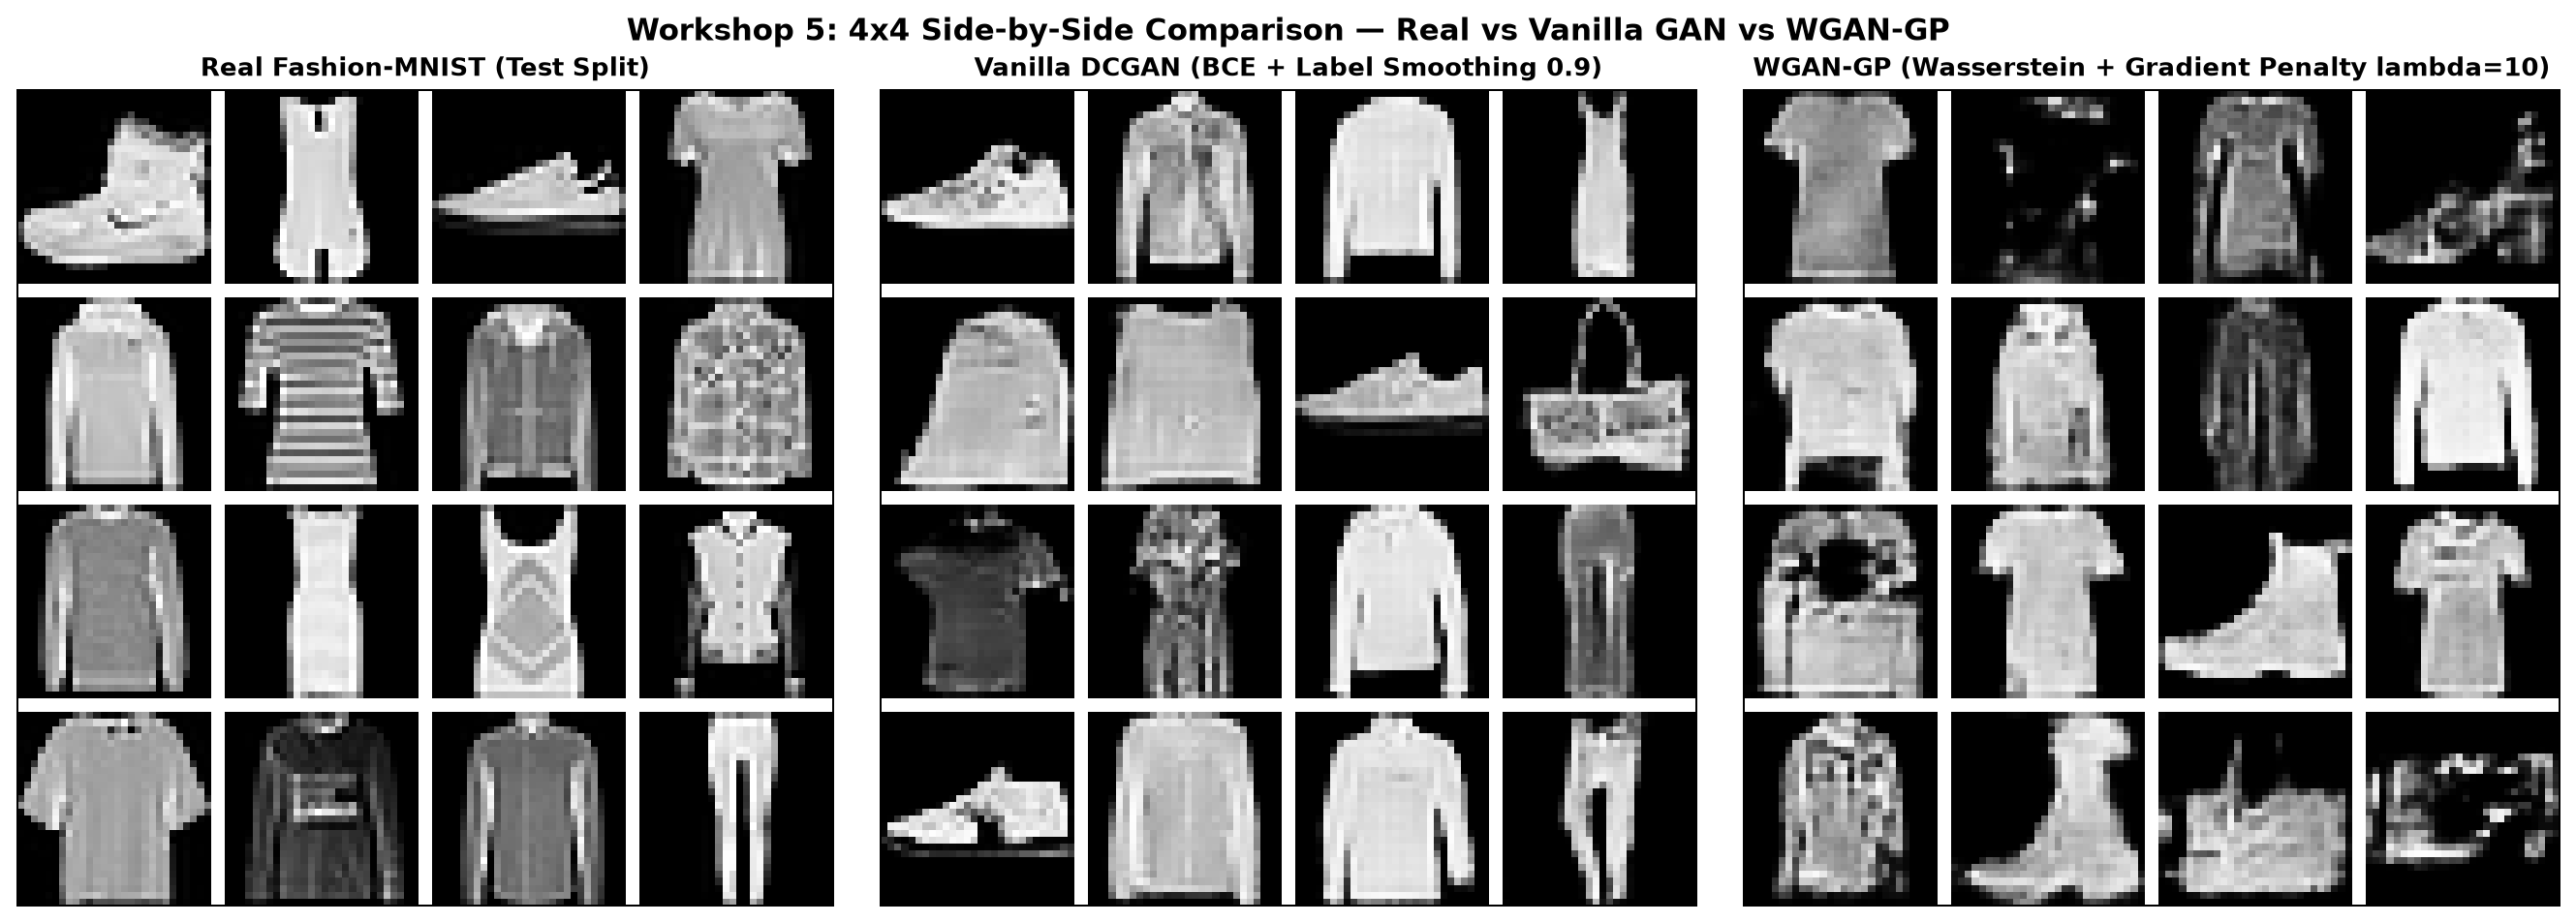

In [10]:
gen_van, ckpt_van = load_generator_checkpoint(BASE / "checkpoints" / "gan_vanilla_best.pt", map_location="cpu")
gen_wgan, ckpt_wgan = load_generator_checkpoint(BASE / "checkpoints" / "gan_wgan_best.pt", map_location="cpu")

van_grid, _ = sample_from_generator(gen_van, 64, device, seed=SEED)
wgan_grid, _ = sample_from_generator(gen_wgan, 64, device, seed=SEED + 1)
grid_path = run_root / "sample_grid_4x4.png"
plot_side_by_side_grid(real_test, van_grid, wgan_grid, grid_size=4, out_path=grid_path)
display(Image(filename=str(grid_path)))

## 8. Generation quality - domain FFD and Inception Score

Standard Inception-V3 metrics do not transfer to grayscale 28x28 garments, so Workshop 5 uses **domain-specific** metrics computed with the frozen Workshop 2 `SmallCNN` (93.05% test accuracy):

- **FFD (Frechet Fashion-MNIST Distance):** Frechet distance between Gaussians fitted to the 128-d global-average-pool features of generated vs real test images. Lower is better; real vs real is 0.
- **Domain Inception Score:** `exp(E[KL(p(y|x) || p(y))])` using the SmallCNN posterior. Rewards confident and diverse samples.
- **Mode coverage:** number of classes receiving more than 2% of the generated mass (10/10 is the target).
- **KL to uniform:** distance of the predicted-class histogram from the uniform distribution.
- **Intra-class L2 diversity:** mean pairwise pixel distance inside each predicted class (a collapse detector).

The cell recomputes the metrics on a fresh sample. Exact values can differ slightly from the report because the RNG stream of the generator depends on the accelerator (MPS/DirectML/CPU), so the saved reference JSON is printed alongside for comparison.

In [11]:
teacher = load_w2_evaluator(BASE.parent / "Workshop_2" / "checkpoints" / "model_best.pt", device)
feats_real, probs_real = extract_features_and_probs(teacher, real_test, device)
is_real_mean, is_real_std = compute_inception_score(probs_real)
real_div = compute_diversity_and_coverage(real_test, probs_real)

van_eval, _ = sample_from_generator(gen_van, EVAL_SAMPLES, device, seed=SEED)
wgan_eval, _ = sample_from_generator(gen_wgan, EVAL_SAMPLES, device, seed=SEED + 1)

rows = []
for name, sample in [("Real test", real_test), ("Vanilla GAN", van_eval), ("WGAN-GP", wgan_eval)]:
    feats, probs = extract_features_and_probs(teacher, sample, device)
    ffd = 0.0 if name == "Real test" else compute_frechet_distance(feats_real, feats)
    is_mean, is_std = compute_inception_score(probs)
    div = compute_diversity_and_coverage(sample, probs)
    rows.append((name, ffd, is_mean, is_std, div))

print(f"metrics on {len(van_eval):,} generated samples per model\n")
print(f"{'model':<14} {'FFD':>8} {'IS':>8} {'modes':>7} {'KL_unif':>9} {'L2_div':>8}")
for name, ffd, is_mean, is_std, div in rows:
    print(f"{name:<14} {ffd:>8.3f} {is_mean:>8.3f} {div['covered_modes_gt_2pct']:>5}/10 {div['kl_to_uniform']:>9.4f} {div['intra_class_l2_diversity']:>8.3f}")

saved = json.loads((BASE / "runs" / "workshop5" / "gan_quality_metrics.json").read_text())
print("\nreference saved by the full 5,000-sample run:")
for key, label in [("real_test_reference", "real test"), ("vanilla_gan", "vanilla"), ("wgan_gp", "wgan-gp")]:
    m = saved[key]
    print(f"  {label:<10} FFD={m['frechet_distance']:.3f} IS={m['inception_score_mean']:.3f} modes={m['covered_modes_gt_2pct']}/10")

metrics on 5,000 generated samples per model

model               FFD       IS   modes   KL_unif   L2_div
Real test         0.000    8.327    10/10    0.0002    8.842
Vanilla GAN       1.823    6.668    10/10    0.0121    8.699
WGAN-GP           5.190    6.110    10/10    0.0263    8.567

reference saved by the full 5,000-sample run:
  real test  FFD=0.000 IS=8.327 modes=10/10
  vanilla    FFD=1.560 IS=6.711 modes=10/10
  wgan-gp    FFD=5.166 IS=6.127 modes=10/10


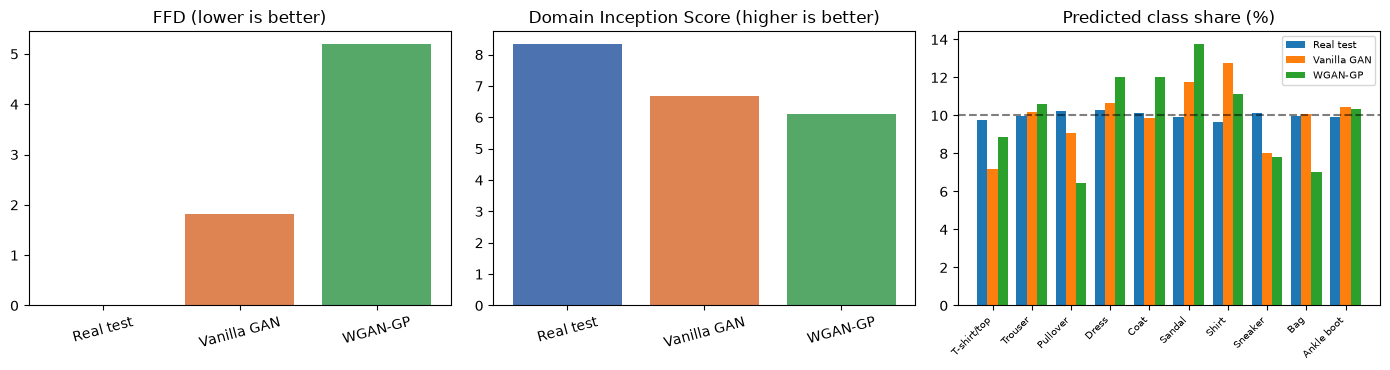

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
names = [r[0] for r in rows]
axes[0].bar(names, [r[1] for r in rows], color=["#4c72b0", "#dd8452", "#55a868"])
axes[0].set_title("FFD (lower is better)")
axes[0].tick_params(axis="x", rotation=15)

axes[1].bar(names, [r[2] for r in rows], color=["#4c72b0", "#dd8452", "#55a868"])
axes[1].set_title("Domain Inception Score (higher is better)")
axes[1].tick_params(axis="x", rotation=15)

x = np.arange(len(CLASS_NAMES))
width = 0.26
for offset, (name, _, _, _, div) in zip([-width, 0, width], rows):
    axes[2].bar(x + offset, [div["class_frequencies"][c] * 100 for c in CLASS_NAMES], width=width, label=name)
axes[2].axhline(10, color="black", linestyle="--", alpha=0.5)
axes[2].set_xticks(x)
axes[2].set_xticklabels(CLASS_NAMES, rotation=45, ha="right", fontsize=7)
axes[2].set_title("Predicted class share (%)")
axes[2].legend(fontsize=7)

fig.tight_layout()
plt.show()

## 9. Data augmentation experiment - step by step

The downstream experiment follows the GAN-augmentation pipeline of Frid-Adar et al.:

1. Each generator produces an unlabeled pool of images.
2. The frozen Workshop 2 `SmallCNN` assigns pseudo-labels and keeps only samples with confidence >= 0.85.
3. The selected synthetic images are ranked by teacher confidence and capped at 3,000; because the teacher is already accurate on easy classes, the pool is weighted toward them.
4. The `SmallCNN` is retrained from scratch under three conditions with everything else fixed: real only, real + vanilla GAN, real + WGAN-GP.

The full 25-epoch retraining is already stored in `runs/workshop5/augmentation_results.json`. The cell below loads those results and then demonstrates the synthetic-set construction (without retraining) so the filtering step is visible.

real train images: 49,000 | synthetic added per condition: 3,000
teacher acceptance rate: vanilla=64.36% | wgan-gp=58.64%

condition                   accuracy  macro F1  ROC-AUC  Shirt F1
real_only                     91.97%    0.9196   0.9953    0.7603
real_plus_vanilla_gan         92.29%    0.9225   0.9954    0.7673
real_plus_wgan_gp             92.25%    0.9224   0.9955    0.7650

W2 reference (30 epochs): 93.05% / F1 0.9302


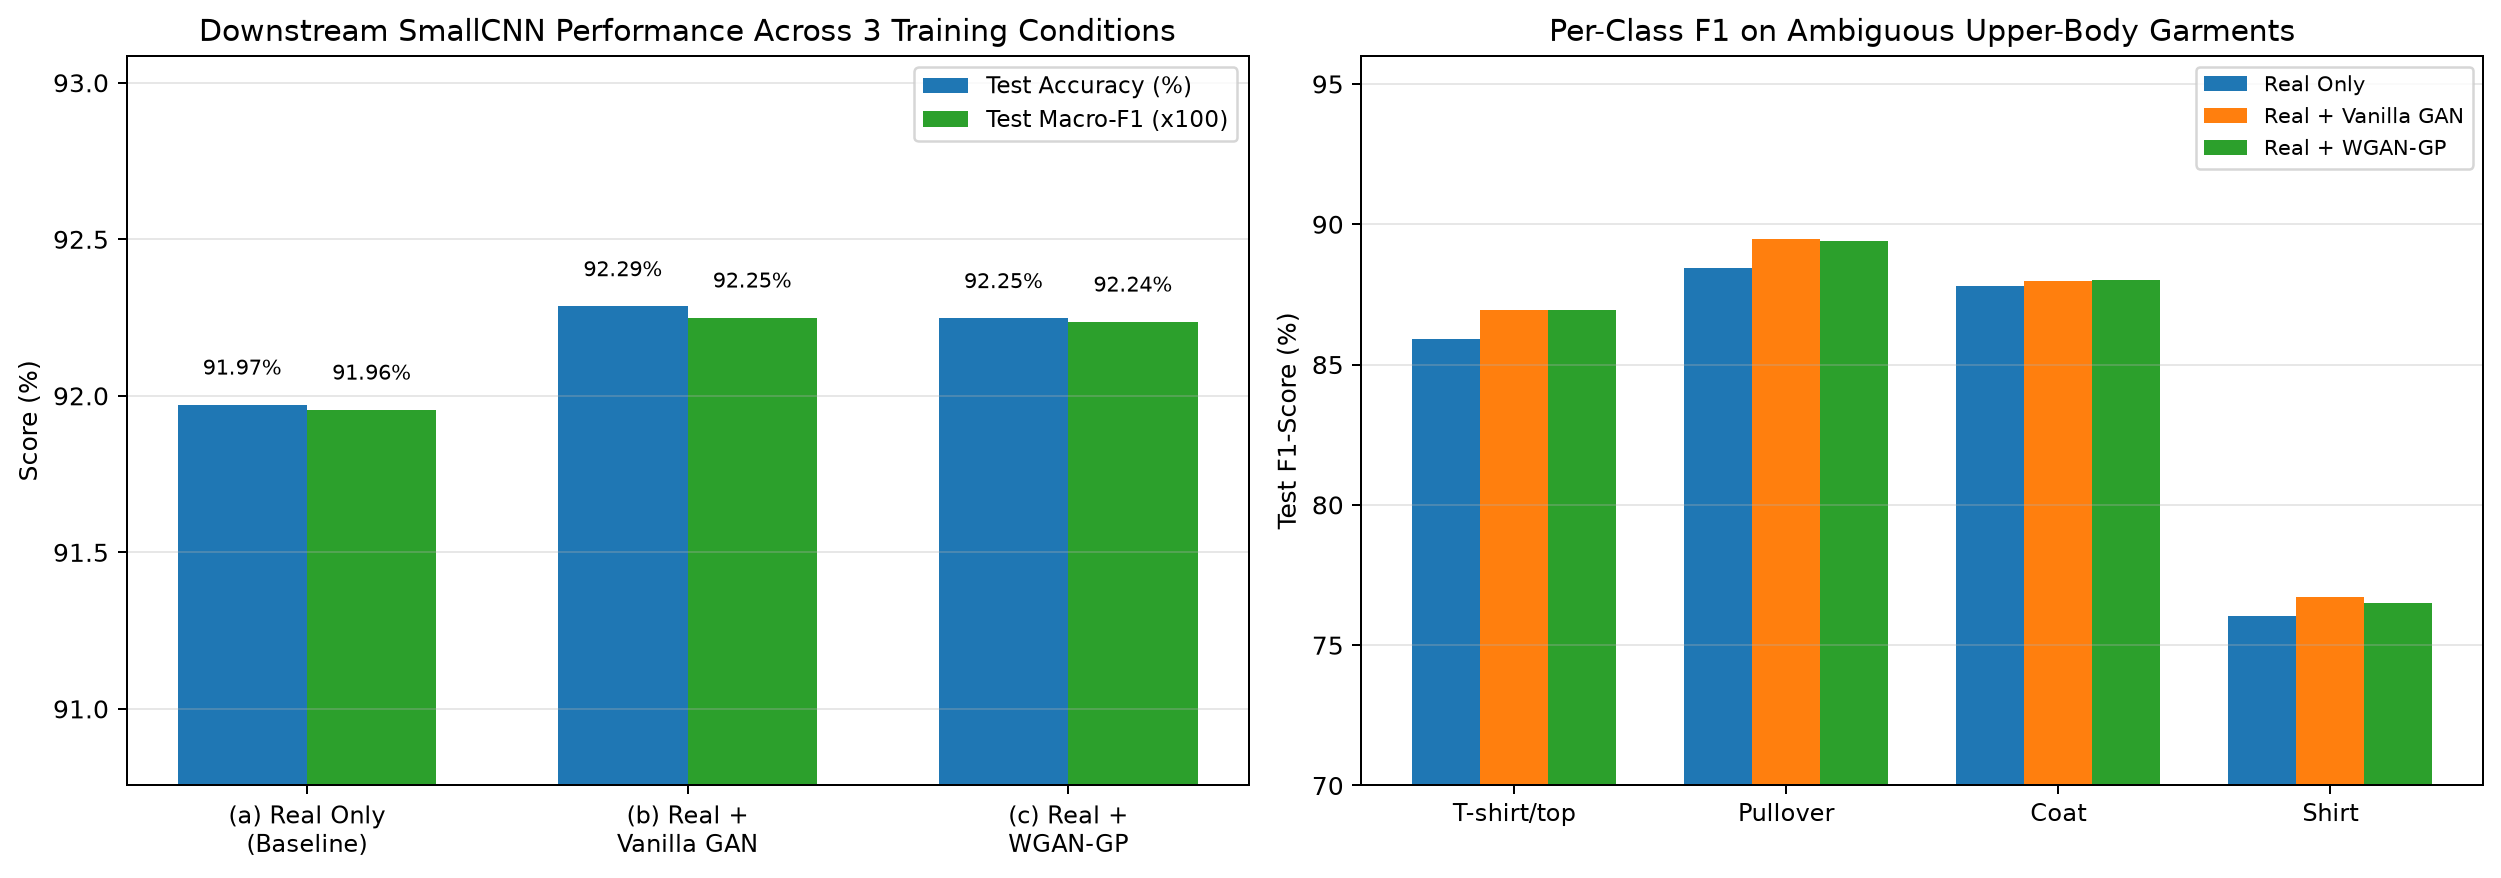

In [13]:
aug = json.loads((BASE / "runs" / "workshop5" / "augmentation_results.json").read_text())
print(f"real train images: {aug['num_real_train']:,} | synthetic added per condition: {aug['num_synthetic_added']:,}")
print(f"teacher acceptance rate: vanilla={aug['vanilla_acceptance_rate']*100:.2f}% | wgan-gp={aug['wgan_gp_acceptance_rate']*100:.2f}%\n")
print(f"{'condition':<26} {'accuracy':>9} {'macro F1':>9} {'ROC-AUC':>8} {'Shirt F1':>9}")
for condition, values in aug["conditions"].items():
    print(f"{condition:<26} {values['accuracy']*100:>8.2f}% {values['f1_macro']:>9.4f} {values['roc_auc_ovr']:>8.4f} {values['per_class_f1']['Shirt']:>9.4f}")
print(f"\nW2 reference (30 epochs): {aug['w2_reference_smallcnn_30ep']['accuracy']*100:.2f}% / F1 {aug['w2_reference_smallcnn_30ep']['f1_macro']:.4f}")
display(Image(filename=str(BASE / "runs" / "workshop5" / "augmentation_comparison.png")))

synthetic pool accepted: 3000 images | teacher acceptance rate: 64.14%
pseudo-label counts: [31, 732, 38, 225, 46, 604, 8, 261, 538, 517]
(high-confidence filtering favours the classes the teacher already knows best)


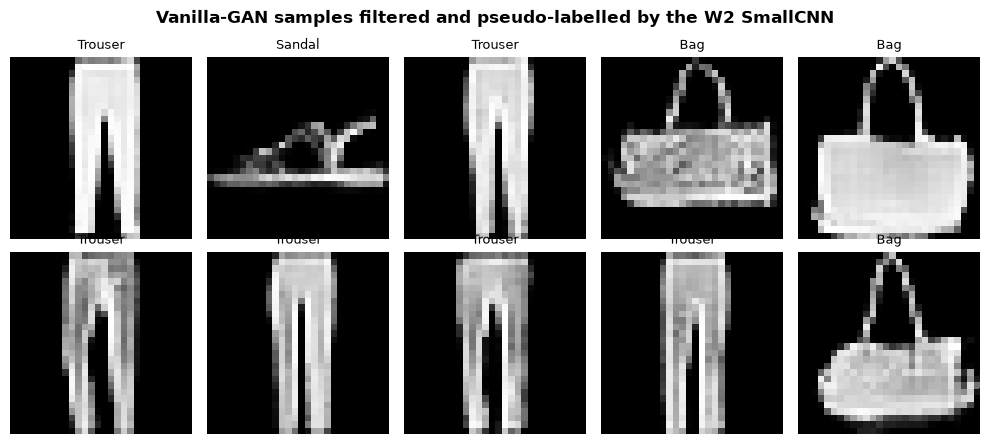

In [14]:
syn_x, syn_y, acceptance = build_synthetic_labeled_set(
    gen_van, teacher, 3000, device, seed=SEED
)
print(f"synthetic pool accepted: {len(syn_x)} images | teacher acceptance rate: {acceptance*100:.2f}%")
print("pseudo-label counts:", np.bincount(syn_y, minlength=10).tolist())
print("(high-confidence filtering favours the classes the teacher already knows best)")

fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for ax, img, label in zip(axes.ravel(), syn_x[:10], syn_y[:10]):
    ax.imshow(img, cmap="gray")
    ax.set_title(CLASS_NAMES[int(label)], fontsize=9)
    ax.axis("off")
fig.suptitle("Vanilla-GAN samples filtered and pseudo-labelled by the W2 SmallCNN", fontweight="bold")
fig.tight_layout()
plt.show()

## 10. Checkpoint verification (deliverable)

The workshop requires saved generators that can be loaded and used for inference. The check below mirrors `src/test_model.py`:

1. Load `checkpoints/gan_vanilla_best.pt` and `checkpoints/gan_wgan_best.pt`.
2. Inspect the stored configuration and generator state.
3. Generate a small batch and verify the output shape/range.
4. Confirm that the checkpoint uses the expected `z_dim` and `num_classes`.

In [15]:
for name, path in [("vanilla", BASE / "checkpoints" / "gan_vanilla_best.pt"), ("wgan_gp", BASE / "checkpoints" / "gan_wgan_best.pt")]:
    ckpt = torch.load(path, map_location="cpu", weights_only=False)
    gen, _ = load_generator_checkpoint(path, map_location="cpu")
    z = torch.randn(4, gen.z_dim)
    with torch.no_grad():
        out = gen(z)
    print(f"{name:<8} | model_type={ckpt.get('model_type')} | epochs={ckpt.get('epochs')} | z_dim={gen.z_dim} | num_classes={gen.num_classes} | out={tuple(out.shape)} | range=[{out.min():.2f}, {out.max():.2f}]")

vanilla  | model_type=vanilla | epochs=100 | z_dim=100 | num_classes=0 | out=(4, 1, 28, 28) | range=[-1.00, 1.00]
wgan_gp  | model_type=wgan_gp | epochs=100 | z_dim=100 | num_classes=0 | out=(4, 1, 28, 28) | range=[-1.00, 0.99]


## 11. Reproducing the full experiments

Commands used for the reported runs (from `Workshop_5/`):

```bash
# 1. Verify Generator, Discriminator, Critic and gradient penalty
python -m src.gan

# 2. Vanilla GAN - 100 epochs, BCE + label smoothing 0.9
python -m src.train_gan --model vanilla --epochs 100 --lr 2e-4 --label-smoothing 0.9

# 3. WGAN-GP - 100 epochs, n_critic=5, lambda_gp=10
python -m src.train_gan --model wgan_gp --epochs 100 --n-critic 5 --lambda-gp 10.0

# 4. Generate 5,000 samples and 4x4 / 8x8 comparison grids
python -m src.generate_samples --vanilla-ckpt checkpoints/gan_vanilla_best.pt \
    --wgan-ckpt checkpoints/gan_wgan_best.pt --num-samples 5000

# 5. Compute FFD, domain IS, mode coverage and diversity
python -m src.evaluate_gan --vanilla-ckpt checkpoints/gan_vanilla_best.pt \
    --wgan-ckpt checkpoints/gan_wgan_best.pt --w2-ckpt ../Workshop_2/checkpoints/model_best.pt

# 6. Three-condition augmentation experiment
python -m src.augment_and_retrain --vanilla-ckpt checkpoints/gan_vanilla_best.pt \
    --wgan-ckpt checkpoints/gan_wgan_best.pt --num-synthetic 2500 --epochs 30
```

**Expected artifacts**

- `checkpoints/gan_vanilla_best.pt` - Vanilla GAN generator.
- `checkpoints/gan_wgan_best.pt` - WGAN-GP generator.
- `runs/workshop5/vanilla_gan/` and `runs/workshop5/wgan_gp/` - per-epoch CSV logs, summaries, TensorBoard events and sample grids every 10 epochs.
- `runs/workshop5/gan_quality_metrics.json` - FFD/IS/coverage/diversity for both models.
- `runs/workshop5/augmentation_results.json` - three-condition downstream comparison.

**Environment note:** the reported runs used an AMD RX 6600 (4 GB) through DirectML in a separate GPU venv; each 100-epoch GAN run took about 11 minutes (~6.5 s/epoch). The notebook demo runs on CPU or Apple MPS with fewer batches and is only a smoke test.

## 12. Summary

- The notebook and the CLI share one implementation: `src/data.py`, `src/gan.py`, `src/train_gan.py`, `src/generate_samples.py`, `src/evaluate_gan.py`, `src/augment_and_retrain.py`; nothing is duplicated for presentation.
- The demo validates the complete adversarial loop (data -> G/D or G/C -> losses -> samples) without touching the reported checkpoints.
- The full experiments (100 epochs per model, 5,000-sample evaluation, 3-condition augmentation) are reproducible from Section 11 with seed 42 and the shared 70/15/15 split.
- Demo artifacts stay isolated in `runs/notebook_demo/` and `checkpoints/notebook_demo/`, so the notebook can be re-run at any time.